# TP 2 — Régression logistique
**Machine Learning · Apprentissage supervisé · Classification**

Ce TP reprend les exemples de la présentation (diapos 13 à 22) :

| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 15 – 16 | Un étudiant réussit-il selon ses heures de révision ? (1 entrée) |
| Exemple 2 | 17 – 18 | Un e-mail est-il un spam ? (3 entrées) |
| Exemple 3 | 19 – 20 | Iris multiclasse : softmax et One-vs-Rest |
| Exemple 4 | 21 | Iris : apprentissage softmax pas à pas |

**Objectifs** : programmer la sigmoïde, la log-loss, la softmax et la descente de gradient **en Python pur**, puis comparer avec **scikit-learn**.

## Rappel de cours (diapos 13 – 14)

1. **Score** : $z = w\cdot x + b$
2. **Probabilité** (sigmoïde) : $p = \sigma(z) = \dfrac{1}{1 + e^{-z}}$ — classe 1 si $p \ge 0{,}5$
3. **Perte (log-loss / entropie croisée)** : $L = -\dfrac{1}{n}\sum_i \big[y_i \ln p_i + (1-y_i)\ln(1-p_i)\big]$ — soit $-\ln p$ si $y = 1$ et $-\ln(1-p)$ si $y = 0$
4. **Gradients** : $\dfrac{\partial L}{\partial w_j} = \text{moy}\big((p - y)\,x_j\big)$, $\dfrac{\partial L}{\partial b} = \text{moy}(p - y)$
5. **Mise à jour** : $w := w - \eta\,\partial L/\partial w$, $b := b - \eta\,\partial L/\partial b$

**Multiclasse (softmax)** : un score $z_k$ par classe, puis $P(k) = \dfrac{e^{z_k}}{\sum_j e^{z_j}}$ ; perte $= -\ln(p_{\text{bonne classe}})$ ; gradients $(p_k - y_k)\,x$.

> Remarque : contrairement à la régression linéaire, il n’y a pas de facteur 2 dans le gradient. C’est une propriété de la log-loss combinée à la sigmoïde.

---
# Partie A — Implémentation from scratch (Python pur)

## Exemple 1 : réussite selon les heures de révision (diapos 15 – 16)

| Heures $x$ | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| Réussite $y$ | 0 | 0 | 1 | 1 |

Départ : $w = 0$, $b = 0$ ; pas $\eta = 0{,}5$.

In [36]:
X = [1, 2, 3, 4]
Y = [0, 0, 1, 1]

### Question 1 — Itération 1 : probabilités et perte
**Réponse.** Avec $w = b = 0$ : $z = 0$ et $p = \sigma(0) = 1/(1 + e^0) = 0{,}5$ pour tous les étudiants. Le modèle n’a encore rien appris : il donne 50 % de chances à chaque classe.
Perte de chaque étudiant : $-\ln(0{,}5) = 0{,}69$, donc perte moyenne = 0,69.

In [37]:
import math

def sigmoide(z):
    return 1 / (1 + math.exp(-z))

def probas(X, w, b):
    return [sigmoide(w * x + b) for x in X]

def log_loss(Y, P):
    # -ln(p) si y = 1, -ln(1 - p) si y = 0, puis moyenne
    return sum(-math.log(p) if y == 1 else -math.log(1 - p) for y, p in zip(Y, P)) / len(Y)

P = probas(X, 0.0, 0.0)
print("p =", P)
print("perte =", log_loss(Y, P))

p = [0.5, 0.5, 0.5, 0.5]
perte = 0.6931471805599453


### Question 2 — Itération 1 : gradients et mise à jour
- $p - y$ = 0,5 ; 0,5 ; −0,5 ; −0,5 et $(p - y)\,x$ = 0,5 ; 1 ; −1,5 ; −2
- $\partial L/\partial w = -2/4 = -0{,}50$ et $\partial L/\partial b = 0/4 = 0$
- $w = 0 - 0{,}5 \times (-0{,}50) = 0{,}25$ et $b = 0$

In [38]:
def gradients(X, Y, w, b):
    P = probas(X, w, b)
    e = [p - y for p, y in zip(P, Y)]
    gw = sum(ei * xi for ei, xi in zip(e, X)) / len(X)
    gb = sum(e) / len(X)
    return gw, gb

def iteration(X, Y, w, b, eta):
    gw, gb = gradients(X, Y, w, b)
    return w - eta * gw, b - eta * gb

gw, gb = gradients(X, Y, 0.0, 0.0)
w, b = iteration(X, Y, 0.0, 0.0, 0.5)
print("grad w =", gw)
print("grad b =", gb)
print("w après itération 1 =", w)
print("b après itération 1 =", b)

grad w = -0.5
grad b = 0.0
w après itération 1 = 0.25
b après itération 1 = 0.0


### Question 3 — Itérations 2 et 3



In [39]:
def afficher(num, X, Y, w, b):
    print(f"--- Itération {num} : w = {w:.4f} ; b = {b:.4f}")
    print(f"{'x':>3} {'z':>6} {'p':>6} {'perte':>6} {'p−y':>6} {'(p−y)x':>7}")
    for x, y in zip(X, Y):
        z = w * x + b; p = sigmoide(z)
        perte = -math.log(p) if y == 1 else -math.log(1 - p)
        print(f"{x:>3} {z:>6.2f} {p:>6.2f} {perte:>6.2f} {p - y:>6.2f} {(p - y) * x:>7.2f}")
    print(f"perte moyenne = {log_loss(Y, probas(X, w, b)):.4f}")

w, b = 0.0, 0.0
etats = []
for k in range(1, 4):
    etats.append((w, b, log_loss(Y, probas(X, w, b))))
    afficher(k, X, Y, w, b)
    w, b = iteration(X, Y, w, b, 0.5)
print(f"\nAprès 3 itérations : w = {w:.4f} ; b = {b:.4f}\n")


--- Itération 1 : w = 0.0000 ; b = 0.0000
  x      z      p  perte    p−y  (p−y)x
  1   0.00   0.50   0.69   0.50    0.50
  2   0.00   0.50   0.69   0.50    1.00
  3   0.00   0.50   0.69  -0.50   -1.50
  4   0.00   0.50   0.69  -0.50   -2.00
perte moyenne = 0.6931
--- Itération 2 : w = 0.2500 ; b = 0.0000
  x      z      p  perte    p−y  (p−y)x
  1   0.25   0.56   0.83   0.56    0.56
  2   0.50   0.62   0.97   0.62    1.24
  3   0.75   0.68   0.39  -0.32   -0.96
  4   1.00   0.73   0.31  -0.27   -1.08
perte moyenne = 0.6250
--- Itération 3 : w = 0.2789 ; b = -0.0744
  x      z      p  perte    p−y  (p−y)x
  1   0.20   0.55   0.80   0.55    0.55
  2   0.48   0.62   0.96   0.62    1.24
  3   0.76   0.68   0.38  -0.32   -0.95
  4   1.04   0.74   0.30  -0.26   -1.04
perte moyenne = 0.6124

Après 3 itérations : w = 0.3051 ; b = -0.1482



### Question 4 — Après ~200 mises à jour : prédire pour 3,5 h


In [40]:
# 1) Continuer l'entraînement à partir des 3 itérations déjà faites (Question 3)
#    w et b contiennent déjà les valeurs après l'itération 3 : on fait les 197 restantes.
print(f"Départ (après 3 itérations) : w = {w:.2f} ; b = {b:.2f}")
for i in range(4, 201):                               # itérations 4 à 200
    w, b = iteration(X, Y, w, b, 0.5)
    if i in (50, 100, 150, 200):                      # quelques étapes pour suivre l'apprentissage
        print(f"itération {i:>3} : w = {w:.2f} ; b = {b:.2f}")

print(f"\nParamètres appris après 200 itérations : w = {w:.2f} ; b = {b:.2f}")

# 2) Pourquoi z = 0 ?
#    Le modèle dit « réussite » si p = σ(z) ≥ 0,5,
#    et σ(z) = 0,5 exactement quand z = 0  (σ(0) = 1 / (1 + e⁰) = 1/2).
#    z > 0 → réussite ; z < 0 → échec : z = 0 est la frontière entre les deux.
print("σ(0) =", sigmoide(0), "→ z = 0 est le point où le modèle hésite à 50 %")

# 3) Frontière de décision : on résout w·x + b = 0  ⇒  x = −b / w
frontiere = -b / w
print(f"Frontière : x = −b / w = −({b:.2f}) / {w:.2f} = {frontiere:.2f} h")

# 4) Étudiant qui a révisé 3,5 h
x_nouveau = 3.5
z = w * x_nouveau + b          # score
p = sigmoide(z)                # probabilité de réussite
print(f"z = {w:.2f} × {x_nouveau} + ({b:.2f}) = {z:.2f}")
print(f"p = σ({z:.2f}) = {p:.2f}")
if p >= 0.5:
    print(f"{x_nouveau} h > {frontiere:.2f} h  et  p = {p:.2f} ≥ 0,5  →  RÉUSSITE")
else:
    print(f"{x_nouveau} h < {frontiere:.2f} h  et  p = {p:.2f} < 0,5  →  ÉCHEC")

Départ (après 3 itérations) : w = 0.31 ; b = -0.15
itération  50 : w = 1.18 ; b = -2.54
itération 100 : w = 1.72 ; b = -3.96
itération 150 : w = 2.09 ; b = -4.94
itération 200 : w = 2.39 ; b = -5.71

Paramètres appris après 200 itérations : w = 2.39 ; b = -5.71
σ(0) = 0.5 → z = 0 est le point où le modèle hésite à 50 %
Frontière : x = −b / w = −(-5.71) / 2.39 = 2.39 h
z = 2.39 × 3.5 + (-5.71) = 2.66
p = σ(2.66) = 0.93
3.5 h > 2.39 h  et  p = 0.93 ≥ 0,5  →  RÉUSSITE


## Exemple 2 : détection de spam, 3 entrées (diapos 17 – 18)

| # | $x_1$ liens | $x_2$ mots suspects | $x_3$ zones en majuscules | $y$ (1 = spam) |
|---|---|---|---|---|
| 1 | 0 | 0 | 1 | 0 |
| 2 | 1 | 0 | 0 | 0 |
| 3 | 2 | 1 | 1 | 1 |
| 4 | 3 | 2 | 0 | 1 |

Départ : tous les poids et le biais à 0 ; $\eta = 0{,}5$.

In [41]:
X2 = [[0, 0, 1],
      [1, 0, 0],
      [2, 1, 1],
      [3, 2, 0]]
Y2 = [0, 0, 1, 1]

def probas_multi(X, w, b):
    return [sigmoide(sum(wj * xj for wj, xj in zip(w, xs)) + b) for xs in X]

def gradients_multi(X, Y, w, b):
    P = probas_multi(X, w, b)
    e = [p - y for p, y in zip(P, Y)]
    n = len(X)
    gw = [sum(e[i] * X[i][j] for i in range(n)) / n for j in range(len(w))]
    return gw, sum(e) / n

def iteration_multi(X, Y, w, b, eta):
    gw, gb = gradients_multi(X, Y, w, b)
    return [wj - eta * gj for wj, gj in zip(w, gw)], b - eta * gb

### Question 5 — Itération 1


In [42]:
w2, b2 = [0.0, 0.0, 0.0], 0.0
gw, gb = gradients_multi(X2, Y2, w2, b2)
w2, b2 = iteration_multi(X2, Y2, w2, b2, 0.5)
print("grad w =", gw)
print("grad b =", gb)
print("w après itération 1 =", w2)
print("b après itération 1 =", b2)

grad w = [-0.5, -0.375, 0.0]
grad b = 0.0
w après itération 1 = [0.25, 0.1875, 0.0]
b après itération 1 = 0.0


### Question 6 — Itérations 2 et 3


In [43]:
w2, b2 = [0.0, 0.0, 0.0], 0.0
suivi = []
for k in range(3):
    w2, b2 = iteration_multi(X2, Y2, w2, b2, 0.5)
    suivi.append((w2, b2, log_loss(Y2, probas_multi(X2, w2, b2))))
    print(f"Après itération {k+1} : w = {[round(v, 3) for v in w2]} ; b = {b2:.3f} ; perte = {suivi[-1][2]:.3f}")


Après itération 1 : w = [0.25, 0.188, 0.0] ; b = 0.000 ; perte = 0.552
Après itération 2 : w = [0.355, 0.291, -0.021] ; b = -0.060 ; perte = 0.507
Après itération 3 : w = [0.419, 0.369, -0.045] ; b = -0.135 ; perte = 0.476


### Question 7 — Après ~300 mises à jour : classer un nouvel e-mail


In [44]:
w2, b2 = [0.0, 0.0, 0.0], 0.0
for _ in range(300):
    w2, b2 = iteration_multi(X2, Y2, w2, b2, 0.5)
nouveau = [2, 1, 1]
z = sum(wj * xj for wj, xj in zip(w2, nouveau)) + b2
p_spam = sigmoide(z)
print("z =", z)
print("p(spam) =", p_spam)
print("→", "SPAM" if p_spam >= 0.5 else "NON-SPAM")

z = 3.4456443323437957
p(spam) = 0.9691009795073167
→ SPAM


## Exemple 3 : Iris multiclasse — softmax et One-vs-Rest

Une fleur du jeu de test Iris (vraie espèce : virginica) reçoit les scores bruts :

| | setosa | versicolor | virginica |
|---|---|---|---|
| score $z$ | −6,08 | 1,95 | 4,13 |

### Question 8 — Appliquer la softmax à la main
**Réponse.** $e^{z}$ = 0,00 ; 7,03 ; 62,18 ; total ≈ 69,2 ; probabilités = 0 % ; 10 % ; 90 % → **virginica (90 %)**.

> La diapo affiche $e^z$ = 7,04 et 62,35 (total 69,39) car elle a calculé à partir des scores non arrondis. Les probabilités finales sont identiques.

In [45]:
def softmax(z):
    ez = [math.exp(v) for v in z]
    total = sum(ez)
    return [v / total for v in ez], ez, total

classes = ["setosa", "versicolor", "virginica"]
z_fleur = [-6.08, 1.95, 4.13]
p, ez, total = softmax(z_fleur)
for c, e, pk in zip(classes, ez, p):
    print(f"{c:<11} e^z = {e:7.2f}   P = {pk:6.1%}")
print("Prédiction :", classes[p.index(max(p))])

setosa      e^z =    0.00   P =   0.0%
versicolor  e^z =    7.03   P =  10.2%
virginica   e^z =   62.18   P =  89.8%
Prédiction : virginica


### Question 9 — One-vs-Rest : normaliser les réponses (diapo 20)
Trois modèles binaires (sigmoïde) répondent séparément : 0,000 ; 0,524 ; 0,915. Leur total vaut 1,439 ≠ 1.

**Réponse.** On divise chaque réponse par le total : 0 % ; 36 % ; 64 %. La prédiction est la même (virginica), mais avec moins d’assurance que la softmax (64 % au lieu de 90 %).

In [48]:
reponses_ovr = [0.000, 0.524, 0.915]
total_ovr = sum(reponses_ovr)
p_ovr = [r / total_ovr for r in reponses_ovr]
print("P(virginica) :", p_ovr)
print("Prédiction :", classes[p_ovr.index(max(p_ovr))])


P(virginica) : [0.0, 0.36414176511466295, 0.635858234885337]
Prédiction : virginica


## Exemple 4 : apprentissage softmax pas à pas (diapo 21)

Une fleur virginica avec un pétale de 5,1 cm × 1,8 cm : $x = (5{,}1 ; 1{,}8)$, $y = (0 ; 0 ; 1)$. Poids et biais à 0, $\eta = 0{,}1$.

### Question 10 — Itération 1
**Réponse.** $z = (0 ; 0 ; 0)$ → $p = (0{,}333 ; 0{,}333 ; 0{,}333)$, perte $= -\ln(0{,}333) = 1{,}099$.
Gradient de la classe $k$ : $(p_k - y_k)\,x$. Pour virginica : $(0{,}333 - 1) \times (5{,}1 ; 1{,}8) = (-3{,}40 ; -1{,}20)$.
Après mise à jour : $w_{\text{virginica}} = (0{,}34 ; 0{,}12)$ et $w_{\text{setosa}} = w_{\text{versicolor}} = (-0{,}17 ; -0{,}06)$.

In [49]:
x_fl = [5.1, 1.8]
y_fl = [0, 0, 1]
W = [[0.0, 0.0] for _ in range(3)]   # un vecteur de poids par classe
B = [0.0, 0.0, 0.0]
eta = 0.1

def scores(W, B, x):
    return [sum(wj * xj for wj, xj in zip(W[k], x)) + B[k] for k in range(3)]

def iteration_softmax(W, B, x, y, eta):
    p, _, _ = softmax(scores(W, B, x))
    for k in range(3):
        g = p[k] - y[k]
        W[k] = [wj - eta * g * xj for wj, xj in zip(W[k], x)]
        B[k] = B[k] - eta * g
    return W, B

p, _, _ = softmax(scores(W, B, x_fl))

grad_virg = [(p[2] - 1) * xj for xj in x_fl]


W, B = iteration_softmax(W, B, x_fl, y_fl, eta)
print("Poids après itération 1 :", [[round(v, 3) for v in Wk] for Wk in W])


Poids après itération 1 : [[-0.17, -0.06], [-0.17, -0.06], [0.34, 0.12]]


### Question 11 — Itérations 2 à 4
**Réponse.** P(virginica) monte : 0,333 → 0,911 → 0,939 → 0,953, et la perte baisse : 1,099 → 0,093 → 0,063 → 0,048. Les poids de la bonne classe augmentent, ceux des autres diminuent : la softmax met les classes **en compétition**.

In [50]:
W = [[0.0, 0.0] for _ in range(3)]; B = [0.0, 0.0, 0.0]
attendus = [(0, 0.333, 1.099), (2.017, 0.911, 0.093), (2.284, 0.939, 0.063), (2.469, 0.953, 0.048)]
for it, (z_att, p_att, l_att) in enumerate(attendus, start=1):
    z = scores(W, B, x_fl)
    p, _, _ = softmax(z)
    print(f"Itération {it} : z(virginica) = {z[2]:.3f} ; P(virginica) = {p[2]:.3f} ; perte = {-math.log(p[2]):.3f}")

    W, B = iteration_softmax(W, B, x_fl, y_fl, eta)

Itération 1 : z(virginica) = 0.000 ; P(virginica) = 0.333 ; perte = 1.099
Itération 2 : z(virginica) = 2.017 ; P(virginica) = 0.911 ; perte = 0.093
Itération 3 : z(virginica) = 2.284 ; P(virginica) = 0.939 ; perte = 0.063
Itération 4 : z(virginica) = 2.469 ; P(virginica) = 0.953 ; perte = 0.048


---
# Partie B — Les mêmes exemples avec des bibliothèques

### Question 12 — Vérifier les calculs intermédiaires avec NumPy, SciPy et scikit-learn
**Réponse.** On refait les itérations avec NumPy (calcul vectoriel). On vérifie les pertes avec `sklearn.metrics.log_loss` et la softmax avec `scipy.special.softmax`.

In [51]:
import numpy as np
from scipy.special import softmax as softmax_scipy, expit   # expit = sigmoïde
from sklearn.metrics import log_loss as log_loss_sk

def gd_logistique_numpy(X, y, eta, nb_iter):
    X = np.array(X, dtype=float).reshape(len(y), -1); y = np.array(y, dtype=float)
    w, b = np.zeros(X.shape[1]), 0.0
    pertes = []
    for _ in range(nb_iter):
        p = expit(X @ w + b)
        pertes.append(log_loss_sk(y, p, labels=[0, 1]))
        w, b = w - eta * X.T @ (p - y) / len(y), b - eta * np.mean(p - y)
    pertes.append(log_loss_sk(y, expit(X @ w + b), labels=[0, 1]))
    return w, b, pertes

w_np1, b_np1, pertes1 = gd_logistique_numpy(X, Y, 0.5, 200)
w_np2, b_np2, pertes2 = gd_logistique_numpy(X2, Y2, 0.5, 300)
print("Ex.1 NumPy : w =", w_np1.round(4), "b =", round(b_np1, 4), "| pertes :", np.round(pertes1[:3], 3))
print("Ex.2 NumPy : w =", w_np2.round(4), "b =", round(b_np2, 4), "| pertes :", np.round(pertes2[:3], 3))
print("Softmax SciPy (fleur Iris) :", softmax_scipy(z_fleur).round(3))

Ex.1 NumPy : w = [2.3904] b = -5.706 | pertes : [0.693 0.625 0.612]
Ex.2 NumPy : w = [1.7594 3.9122 0.6846] b = -4.6698 | pertes : [0.693 0.552 0.507]
Softmax SciPy (fleur Iris) : [0.    0.102 0.898]


### Question 13 — `LogisticRegression` de scikit-learn
**Réponse.** On entraîne `LogisticRegression()` sur les mêmes données. Ses **poids ne sont pas les mêmes** que ceux de la diapo, pour deux raisons :
1. **Régularisation** : par défaut `C = 1.0`, scikit-learn pénalise les grands poids (modèle plus prudent).
2. **Données parfaitement séparables** : sans régularisation, la log-loss peut toujours baisser en augmentant les poids, et il n’existe pas de minimum fini. C’est pour cela que la diapo arrête la descente de gradient après un nombre fixé d’itérations (200 ou 300).

Ce qui doit concorder, ce sont donc les **décisions** : la même frontière (≈ 2,4 – 2,5 h), la même classe pour 3,5 h et la même classe pour le nouvel e-mail.

In [52]:
from sklearn.linear_model import LogisticRegression

Xa = np.array(X).reshape(-1, 1)
lr1 = LogisticRegression().fit(Xa, Y)
p35 = lr1.predict_proba([[3.5]])[0, 1]
print(f"Ex.1 : w = {lr1.coef_[0, 0]:.3f} ; b = {lr1.intercept_[0]:.3f} ; frontière = {-lr1.intercept_[0] / lr1.coef_[0, 0]:.2f} h ; p(3,5 h) = {p35:.2f} → classe {lr1.predict([[3.5]])[0]}")

lr2 = LogisticRegression().fit(X2, Y2)
pm = lr2.predict_proba([nouveau])[0, 1]
print(f"Ex.2 : w = {lr2.coef_[0].round(3)} ; b = {lr2.intercept_[0]:.3f} ; p(spam) nouvel e-mail = {pm:.2f} → classe {lr2.predict([nouveau])[0]}")

# Avec une régularisation très faible (C grand), les poids augmentent fortement : il n'existe pas de minimum fini.
for C in [1, 10, 1000]:
    m = LogisticRegression(C=C, max_iter=10000).fit(Xa, Y)
    print(f"   C = {C:>5} : w = {m.coef_[0, 0]:7.2f}  b = {m.intercept_[0]:7.2f}  frontière = {-m.intercept_[0] / m.coef_[0, 0]:.2f} h")

Ex.1 : w = 0.958 ; b = -2.395 ; frontière = 2.50 h ; p(3,5 h) = 0.72 → classe 1
Ex.2 : w = [0.784 0.604 0.16 ] ; b = -1.672 ; p(spam) nouvel e-mail = 0.66 → classe 1
   C =     1 : w =    0.96  b =   -2.40  frontière = 2.50 h
   C =    10 : w =    2.65  b =   -6.63  frontière = 2.50 h
   C =  1000 : w =    9.24  b =  -23.11  frontière = 2.50 h


### Question 14 — Reproduire l’exemple Iris réel des diapos 19 – 20
**Réponse.** La fleur de la diapo est la **première fleur du jeu de test** obtenu avec : 30 % de test (45 fleurs), `random_state=42`, stratification, et des mesures standardisées (`StandardScaler`). On retrouve :
- les scores bruts −6,08 ; 1,95 ; 4,13 (`decision_function`) ;
- softmax : 0 % ; 10 % ; 90 % ;
- One-vs-Rest : 0,000 ; 0,524 ; 0,915 → 0 % ; 36 % ; 64 % ;
- précision sur les 45 fleurs de test : 91,1 % (softmax) et 84,4 % (One-vs-Rest).

Enfin, on calcule nous-mêmes en Python pur le score $z = W\cdot x + b$ à partir des poids appris par scikit-learn, puis on applique notre `softmax` de la Partie A.

In [53]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier

Xi, yi = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.3, random_state=42, stratify=yi)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

soft = LogisticRegression().fit(Xtr_s, ytr)               # softmax (multinomial)
ovr = OneVsRestClassifier(LogisticRegression()).fit(Xtr_s, ytr)

fleur = Xte_s[0]
print("Fleur de test n°0 : mesures =", Xte[0], "| vraie espèce :", classes[yte[0]])
z_sk = soft.decision_function([fleur])[0]
print("Scores z (scikit-learn) :", z_sk.round(2))
print("Softmax (scikit-learn)  :", soft.predict_proba([fleur])[0].round(3))

# Notre softmax (Partie A) appliquée aux scores calculés en Python pur avec les poids appris
z_pur = [sum(wj * xj for wj, xj in zip(soft.coef_[k], fleur)) + soft.intercept_[k] for k in range(3)]
p_pur, _, _ = softmax(z_pur)
print("Softmax (Python pur)    :", [round(v, 3) for v in p_pur])

reponses = [est.predict_proba([fleur])[0, 1] for est in ovr.estimators_]
print("Réponses One-vs-Rest brutes :", np.round(reponses, 3), "→ normalisées :", ovr.predict_proba([fleur])[0].round(2))

Fleur de test n°0 : mesures = [7.3 2.9 6.3 1.8] | vraie espèce : virginica
Scores z (scikit-learn) : [-6.08  1.95  4.13]
Softmax (scikit-learn)  : [0.    0.101 0.899]
Softmax (Python pur)    : [0.0, 0.101, 0.899]
Réponses One-vs-Rest brutes : [0.    0.524 0.915] → normalisées : [0.   0.36 0.64]


### Question 15 — Exemple 4 avec NumPy et SciPy
**Réponse.** Même calcul sous forme matricielle : $W \leftarrow W - \eta\,(p - y)\,x^\top$.

In [54]:
Wn, Bn = np.zeros((3, 2)), np.zeros(3)
xv, yv = np.array(x_fl), np.array(y_fl)
p_virg_np = []
for it in range(4):
    p = softmax_scipy(Wn @ xv + Bn)
    p_virg_np.append(p[2])
    Wn -= 0.1 * np.outer(p - yv, xv); Bn -= 0.1 * (p - yv)
print("P(virginica) par itération (NumPy) :", np.round(p_virg_np, 3))

P(virginica) par itération (NumPy) : [0.333 0.911 0.939 0.953]


---
# Partie C — Comparaison et validation
### Question 16 — Les résultats concordent-ils ?

In [55]:
import pandas as pd

# Python pur (exemple 4) recalculé pour la comparaison
W = [[0.0, 0.0] for _ in range(3)]; B = [0.0, 0.0, 0.0]; p_virg_pur = []
for _ in range(4):
    p_virg_pur.append(softmax(scores(W, B, x_fl))[0][2]); W, B = iteration_softmax(W, B, x_fl, y_fl, 0.1)

lignes = [
    ("Ex.1 w (200 it.)", 2.39, w200, w_np1[0], "—"),
    ("Ex.1 b (200 it.)", -5.71, b200, b_np1, "—"),
    ("Ex.1 classe pour 3,5 h", 1, int(sigmoide(w200 * 3.5 + b200) >= 0.5), int(expit(w_np1[0] * 3.5 + b_np1) >= 0.5), lr1.predict([[3.5]])[0]),
    ("Ex.1 frontière (h)", 2.4, -b200 / w200, -b_np1 / w_np1[0], -lr1.intercept_[0] / lr1.coef_[0, 0]),
    ("Ex.2 p(spam) nouvel e-mail", 0.97, p_spam, expit(w_np2 @ nouveau + b_np2), pm),
    ("Ex.2 classe nouvel e-mail", 1, int(p_spam >= 0.5), int(expit(w_np2 @ nouveau + b_np2) >= 0.5), lr2.predict([nouveau])[0]),
    ("Ex.3 P(virginica) softmax", 0.90, softmax(z_fleur)[0][2], softmax_scipy(z_fleur)[2], soft.predict_proba([fleur])[0, 2]),
    ("Ex.3 P(virginica) OvR", 0.64, p_ovr[2], "—", ovr.predict_proba([fleur])[0, 2]),
    ("Ex.4 P(virginica) itération 4", 0.953, p_virg_pur[3], p_virg_np[3], "—"),
]
tableau = pd.DataFrame(lignes, columns=["Grandeur", "Diapo", "Python pur", "NumPy / SciPy", "scikit-learn"])
display(tableau)

assert abs(w200 - w_np1[0]) < 1e-9 and abs(b200 - b_np1) < 1e-9          # même algorithme, mêmes nombres
assert np.allclose(w2 + [b2], list(w_np2) + [b_np2], atol=1e-9)
assert np.allclose(p_virg_pur, p_virg_np, atol=1e-12)
assert lr1.predict([[3.5]])[0] == 1 and lr2.predict([nouveau])[0] == 1     # mêmes décisions que la diapo
print("✅ Python pur = NumPy, et scikit-learn prend les mêmes décisions que les diapos.")

,Grandeur,Diapo,Python pur,NumPy / SciPy,scikit-learn
0,Ex.1 w (200 it.),2.390,2.390406,2.390406,—
1,Ex.1 b (200 it.),-5.710,-5.705971,-5.705971,—
2,"Ex.1 classe pour 3,5 h",1.000,1.000000,1,1
3,Ex.1 frontière (h),2.400,2.387030,2.38703,2.499991
4,Ex.2 p(spam) nouvel e-mail,0.970,0.969101,0.969101,0.659278
5,Ex.2 classe nouvel e-mail,1.000,1.000000,1,1
6,Ex.3 P(virginica) softmax,0.900,0.898409,0.898409,0.898519
7,Ex.3 P(virginica) OvR,0.640,0.635858,—,0.635613
8,Ex.4 P(virginica) itération 4,0.953,0.953042,0.953042,—


✅ Python pur = NumPy, et scikit-learn prend les mêmes décisions que les diapos.


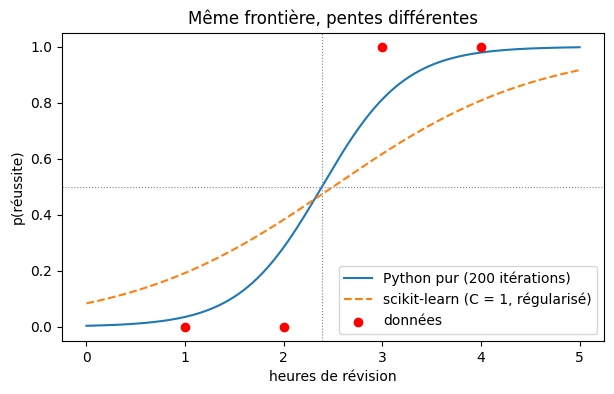

In [56]:
import matplotlib.pyplot as plt
xs = np.linspace(0, 5, 200)
plt.figure(figsize=(7, 4))
plt.plot(xs, [sigmoide(w200 * v + b200) for v in xs], label="Python pur (200 itérations)")
plt.plot(xs, lr1.predict_proba(xs.reshape(-1, 1))[:, 1], "--", label="scikit-learn (C = 1, régularisé)")
plt.scatter(X, Y, color="red", zorder=5, label="données")
plt.axhline(0.5, color="gray", lw=0.8, ls=":"); plt.axvline(-b200 / w200, color="gray", lw=0.8, ls=":")
plt.xlabel("heures de révision"); plt.ylabel("p(réussite)"); plt.legend(); plt.title("Même frontière, pentes différentes")
plt.show()